In [ ]:
# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))


In [3]:
# If needed, uncomment and run once:
# %pip install pandas numpy matplotlib seaborn openpyxl scipy scikit-learn jinja2

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
TARGET = "gallstone_status"

In [17]:
import warnings
warnings.filterwarnings("ignore")

## 1. Load and inspect the data

In [4]:
def find_data_file():
    candidates = [ROOT / "data/raw/dataset_gallstone", ROOT / "data/raw/dataset_gallstone.xlsx"]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("Place dataset_gallstone or dataset_gallstone.xlsx in data/raw.")

DATA_PATH = find_data_file()
df = pd.read_excel(DATA_PATH) if DATA_PATH.suffix.lower() == ".xlsx" else pd.read_csv(DATA_PATH)

# Remove spreadsheet-export index columns only when they exactly behave like a row index.
index_like = [c for c in df.columns if str(c).startswith("Unnamed:") or str(c).strip() == ""]
for col in index_like:
    if df[col].is_unique and df[col].notna().all():
        df = df.drop(columns=col)

print(f"Loaded {DATA_PATH} | {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded dataset_gallstone | 319 rows × 39 columns


,gallstone_status,age,gender,comorbidity,cad,hypothyroidism,hyperlipidemia,dm,height,weight,bmi,tbw,ecw,icw,ecf_tbw,tbfr_pct,lm_pct,protein_pct,vfr,bm,mm,obesity_pct,tfc,vfa,vma_kg,hfa,glucose,tc,ldl,hdl,triglyceride,ast,alt,alp,creatinine,gfr,crp,hgb,vitamin_d
0,0,50,0,0,0,0,0,0,185,92.80,27.10,52.90,21.20,31.70,40.00,19.20,80.84,18.88,9,3.70,71.40,23.40,17.80,10.60,39.70,0,102.00,250.00,175.00,40.00,134.00,20.00,22.00,87.00,0.82,112.47,0.00,16.00,33.00
1,0,47,0,1,0,0,0,0,176,94.50,30.50,43.10,19.50,23.60,45.00,32.80,67.20,16.68,15,3.20,60.30,38.80,31.00,18.40,32.70,0,94.00,172.00,108.00,43.00,103.00,14.00,13.00,46.00,0.87,107.10,0.00,14.40,25.00
2,0,61,0,0,0,0,0,0,171,91.10,31.20,47.20,20.10,27.10,43.00,27.30,72.67,16.35,15,3.30,62.90,41.70,24.90,16.20,34.00,0,103.00,179.00,124.00,43.00,69.00,18.00,14.00,66.00,1.25,65.51,0.00,16.20,30.20
3,0,41,0,0,0,0,0,0,168,67.70,24.00,41.40,17.00,24.40,41.00,15.80,84.19,16.90,6,2.90,54.10,9.00,10.70,6.50,29.20,1,69.00,173.00,73.00,59.00,53.00,20.00,12.00,34.00,1.02,94.10,0.00,15.40,35.40
4,0,42,0,0,0,0,0,0,178,89.60,28.30,51.40,20.00,31.40,39.00,20.00,80.02,16.81,8,3.50,68.20,28.60,17.90,10.40,37.40,2,109.00,205.00,154.00,30.00,326.00,27.00,54.00,71.00,0.82,112.47,0.00,16.80,40.60


In [5]:
df.info()
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100),
    "unique": df.nunique(dropna=True),
}).sort_values(["missing_pct", "unique"], ascending=[False, True]))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gallstone_status  319 non-null    int64  
 1   age               319 non-null    int64  
 2   gender            319 non-null    int64  
 3   comorbidity       319 non-null    int64  
 4   cad               319 non-null    int64  
 5   hypothyroidism    319 non-null    int64  
 6   hyperlipidemia    319 non-null    int64  
 7   dm                319 non-null    int64  
 8   height            319 non-null    int64  
 9   weight            319 non-null    float64
 10  bmi               319 non-null    float64
 11  tbw               319 non-null    float64
 12  ecw               319 non-null    float64
 13  icw               319 non-null    float64
 14  ecf_tbw           319 non-null    float64
 15  tbfr_pct          319 non-null    float64
 16  lm_pct            319 non-null    float64
 1

,dtype,non_null,missing,missing_pct,unique
gallstone_status,int64,319,0,0.00,2
gender,int64,319,0,0.00,2
cad,int64,319,0,0.00,2
hypothyroidism,int64,319,0,0.00,2
hyperlipidemia,int64,319,0,0.00,2
dm,int64,319,0,0.00,2
comorbidity,int64,319,0,0.00,4
hfa,int64,319,0,0.00,5
vfr,int64,319,0,0.00,22
bm,float64,319,0,0.00,25


## 2. Data-quality audit

In [6]:
duplicate_rows = int(df.duplicated().sum())
constant_cols = df.columns[df.nunique(dropna=False) <= 1].tolist()
infinite_counts = pd.Series({c: np.isinf(pd.to_numeric(df[c], errors="coerce")).sum() for c in df.columns})

print(f"Exact duplicate rows: {duplicate_rows}")
print(f"Constant columns: {constant_cols or 'None'}")
print(f"Infinite numeric values: {int(infinite_counts.sum())}")
assert TARGET in df.columns, f"Expected target column '{TARGET}' is missing"
print("Target values:", sorted(df[TARGET].dropna().unique().tolist()))

Exact duplicate rows: 0
Constant columns: None
Infinite numeric values: 0
Target values: [0, 1]


In [7]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
if missing.empty:
    print("No missing values detected.")
else:
    plt.figure(figsize=(10, max(3, len(missing) * 0.3)))
    sns.barplot(x=missing.values, y=missing.index, color="#4C72B0")
    plt.xlabel("Missing values (%)"); plt.ylabel(""); plt.title("Missingness by feature")
    plt.show()

No missing values detected.


## 3. Feature roles and descriptive statistics

Feature roles follow the supplied category definitions. Gender, comorbidity, CAD, hypothyroidism, hyperlipidemia, diabetes mellitus, and HFA are categorical even though stored as numbers. Continuous visualizations exclude these fields and the target. Gallstone status is 0 = Yes and 1 = No; display labels leave the source values unchanged.

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
# Encoded categories are excluded regardless of dtype or observed cardinality.
categorical_fields = ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
coded_categorical = [c for c in categorical_fields if c in df]


continuous_cols = [c for c in numeric_cols if c not in coded_categorical + [TARGET]]
other_categorical = [c for c in df.columns if c not in numeric_cols and c not in coded_categorical and c != TARGET]
categorical_cols = coded_categorical + other_categorical

print("Coded categorical:", coded_categorical)
print("Continuous numeric:", continuous_cols)
display(df[continuous_cols].describe().T.assign(
    median=df[continuous_cols].median(),
    skew=df[continuous_cols].skew()
).sort_values("skew", key=abs, ascending=False))

Coded categorical: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
Continuous numeric: ['age', 'height', 'weight', 'bmi', 'tbw', 'ecw', 'icw', 'ecf_tbw', 'tbfr_pct', 'lm_pct', 'protein_pct', 'vfr', 'bm', 'mm', 'obesity_pct', 'tfc', 'vfa', 'vma_kg', 'glucose', 'tc', 'ldl', 'hdl', 'triglyceride', 'ast', 'alt', 'alp', 'creatinine', 'gfr', 'crp', 'hgb', 'vitamin_d']


,count,mean,std,min,25%,50%,75%,max,median,skew
obesity_pct,319.00,35.85,109.80,0.40,13.90,25.60,41.75,"1,954.00",25.60,16.87
alt,319.00,26.86,27.88,3.00,14.25,19.00,30.00,372.00,19.00,7.28
ast,319.00,21.68,16.70,8.00,15.00,18.00,23.00,195.00,18.00,6.99
hdl,319.00,49.48,17.72,25.00,40.00,46.50,56.00,273.00,46.50,6.53
glucose,319.00,108.69,44.85,69.00,92.00,98.00,109.00,575.00,98.00,5.94
crp,319.00,1.85,4.99,0.00,0.00,0.21,1.61,43.40,0.21,5.41
triglyceride,319.00,144.50,97.90,1.39,83.00,119.00,172.00,838.00,119.00,2.79
gfr,319.00,100.82,16.97,10.60,94.17,104.00,110.75,132.00,104.00,-1.81
vfa,319.00,12.17,5.26,0.90,8.57,11.59,15.10,41.00,11.59,1.06
icw,319.00,23.63,5.35,13.80,19.30,23.00,27.55,57.10,23.00,0.95


In [9]:
if categorical_cols:
    category_summary = pd.concat([
        df[c].value_counts(dropna=False).rename("count").to_frame()
          .assign(percent=lambda x: x["count"] / len(df) * 100, feature=c)
          .rename_axis("value").reset_index()
        for c in categorical_cols
    ], ignore_index=True)
    display(category_summary[["feature", "value", "count", "percent"]])

,feature,value,count,percent
0,gender,0,162,50.78
1,gender,1,157,49.22
2,comorbidity,0,217,68.03
3,comorbidity,1,99,31.03
4,comorbidity,3,2,0.63
5,comorbidity,2,1,0.31
6,cad,0,307,96.24
7,cad,1,12,3.76
8,hypothyroidism,0,310,97.18
9,hypothyroidism,1,9,2.82


## 4. Target balance

,count,percent
Gallstone Status,,
Gallstone Present,161,50.47
Gallstone Absent,158,49.53


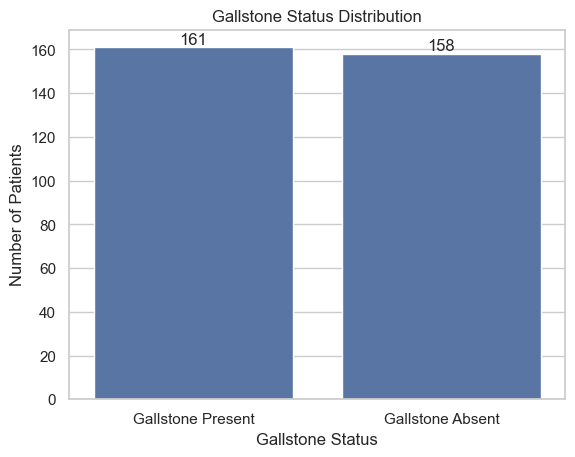

In [10]:
# Human-readable labels for visualization
target_labels = {
    0: "Gallstone Present",
    1: "Gallstone Absent"
}

# -------------------------
# Target summary table
# -------------------------
target_counts = (
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percent": target_counts / len(df) * 100
})

# Replace 0/1 with meaningful category names
target_summary.index = target_summary.index.map(
    lambda x: target_labels.get(x, x)
)

target_summary.index.name = "Gallstone Status"

display(target_summary)


# -------------------------
# Target distribution plot
# -------------------------

# Create label only for visualization
plot_df = df.copy()
plot_df["Gallstone Status"] = plot_df[TARGET].map(target_labels)

ax = sns.countplot(
    data=plot_df,
    x="Gallstone Status",
    order=["Gallstone Present", "Gallstone Absent"],
    color="#4C72B0"
)

ax.bar_label(ax.containers[0])

ax.set_title("Gallstone Status Distribution")
ax.set_xlabel("Gallstone Status")
ax.set_ylabel("Number of Patients")

plt.show()


## 5. Univariate distributions

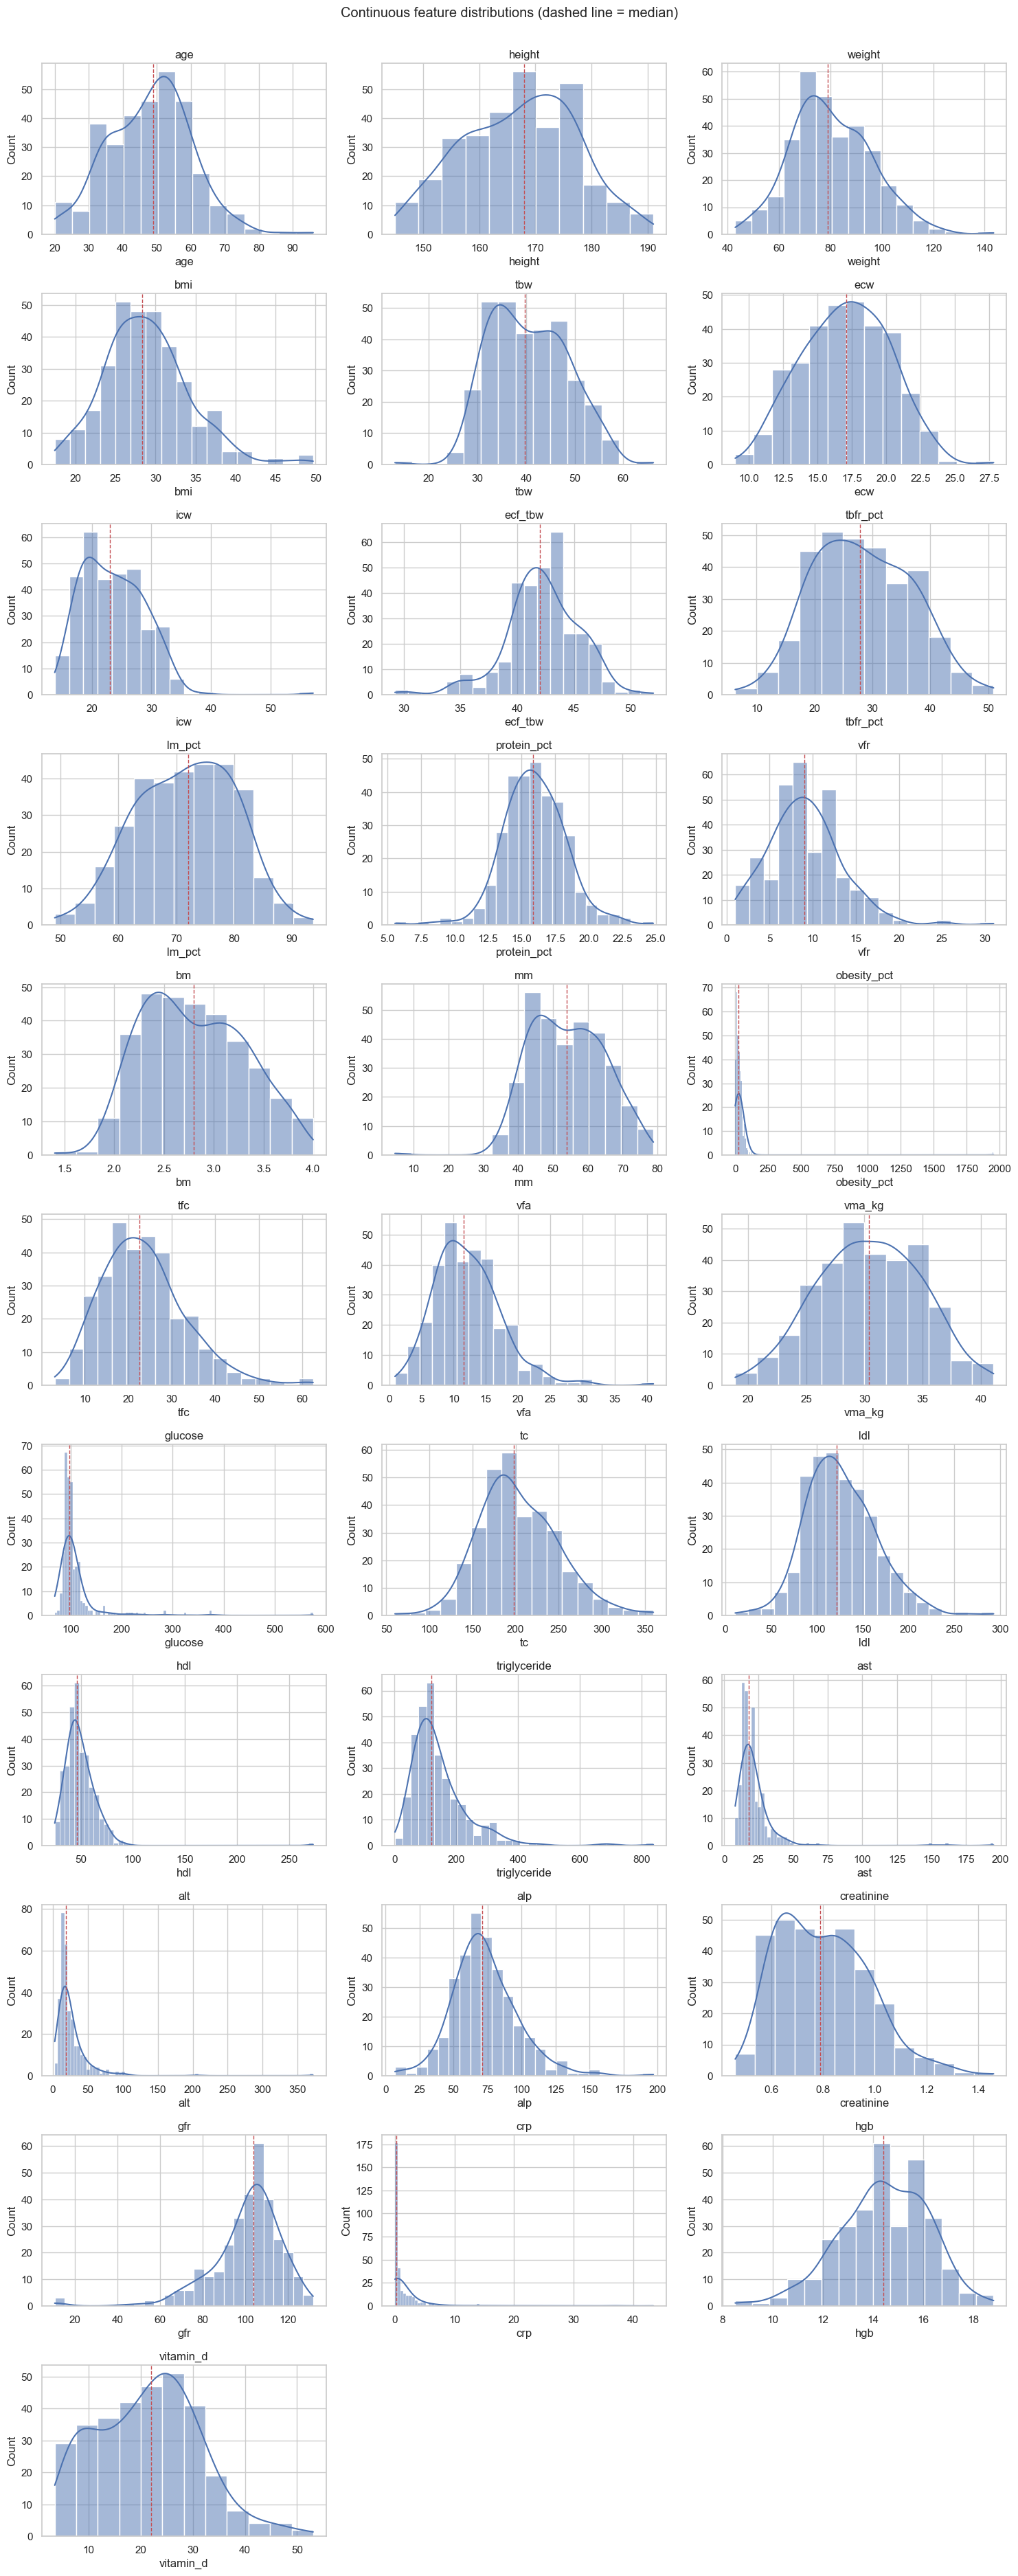

In [11]:
ncols = 3
nrows = int(np.ceil(len(continuous_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.4 * nrows))
for ax, col in zip(np.ravel(axes), continuous_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.axvline(df[col].median(), color="#C44E52", linestyle="--", linewidth=1)
    ax.set_title(col)
for ax in np.ravel(axes)[len(continuous_cols):]: ax.remove()
fig.suptitle("Continuous feature distributions (dashed line = median)", y=1.002)
plt.tight_layout(); plt.show()

### 5.1 Skewness and candidate statistical transformations

As a practical guide, `|skew| < 0.5` is fairly symmetric, `0.5–1` is moderately skewed, and `|skew| > 1` is highly skewed. These are heuristics—not automatic deletion or transformation rules. Extreme values must first be checked against the source and clinical ranges. For predictive modelling, fit any transformation on the training split only.

,skewness,absolute_skew,severity
obesity_pct,16.87,16.87,high
alt,7.28,7.28,high
ast,6.99,6.99,high
hdl,6.53,6.53,high
glucose,5.94,5.94,high
crp,5.41,5.41,high
triglyceride,2.79,2.79,high
gfr,-1.81,1.81,high
vfa,1.06,1.06,high
icw,0.95,0.95,moderate


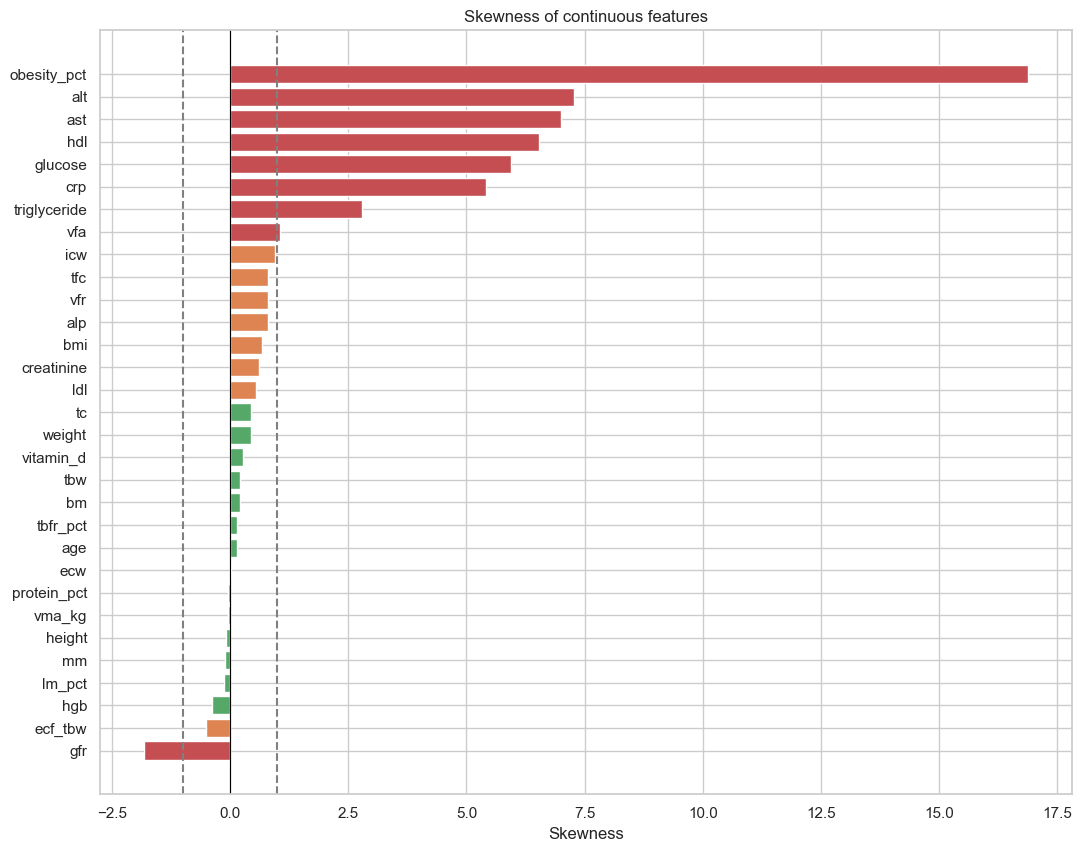

In [12]:
# Rank continuous features by Fisher-Pearson skewness.
skewness = df[continuous_cols].skew().sort_values(key=abs, ascending=False)
skew_table = skewness.rename("skewness").to_frame()
skew_table["absolute_skew"] = skew_table["skewness"].abs()
skew_table["severity"] = pd.cut(
    skew_table["absolute_skew"], bins=[-np.inf, 0.5, 1, np.inf],
    labels=["fairly symmetric", "moderate", "high"]
)
display(skew_table)

plot_skew = skewness.sort_values()
bar_colors = np.where(plot_skew.abs() > 1, "#C44E52",
                      np.where(plot_skew.abs() >= 0.5, "#DD8452", "#55A868"))
plt.figure(figsize=(11, max(7, len(plot_skew) * 0.28)))
plt.barh(plot_skew.index, plot_skew.values, color=bar_colors)
plt.axvline(-1, color="grey", linestyle="--"); plt.axvline(1, color="grey", linestyle="--")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Skewness"); plt.ylabel(""); plt.title("Skewness of continuous features")
plt.tight_layout(); plt.show()

In [13]:
# Data-driven transformation suggestions. Review units and suspicious values first.
def transformation_suggestion(feature, values, skew):
    if abs(skew) < 0.5:
        return "Keep original"
    if abs(skew) < 1:
        return "Usually keep; compare with Yeo-Johnson if the model benefits"
    if skew > 0 and values.min() >= 0:
        prefix = "Validate extreme values first; " if abs(skew) >= 3 else ""
        return prefix + "compare log1p with Yeo-Johnson"
    return "Compare Yeo-Johnson with the original feature"

transform_plan = skew_table.copy()
transform_plan["minimum"] = df[transform_plan.index].min()
transform_plan["maximum"] = df[transform_plan.index].max()
transform_plan["suggestion"] = [
    transformation_suggestion(c, df[c].dropna(), transform_plan.loc[c, "skewness"])
    for c in transform_plan.index
]
display(transform_plan.query("absolute_skew >= 0.5"))

,skewness,absolute_skew,severity,minimum,maximum,suggestion
obesity_pct,16.87,16.87,high,0.40,"1,954.00",Validate extreme values first; compare log1p w...
alt,7.28,7.28,high,3.00,372.00,Validate extreme values first; compare log1p w...
ast,6.99,6.99,high,8.00,195.00,Validate extreme values first; compare log1p w...
hdl,6.53,6.53,high,25.00,273.00,Validate extreme values first; compare log1p w...
glucose,5.94,5.94,high,69.00,575.00,Validate extreme values first; compare log1p w...
crp,5.41,5.41,high,0.00,43.40,Validate extreme values first; compare log1p w...
triglyceride,2.79,2.79,high,1.39,838.00,compare log1p with Yeo-Johnson
gfr,-1.81,1.81,high,10.60,132.00,Compare Yeo-Johnson with the original feature
vfa,1.06,1.06,high,0.90,41.00,compare log1p with Yeo-Johnson
icw,0.95,0.95,moderate,13.80,57.10,Usually keep; compare with Yeo-Johnson if the ...


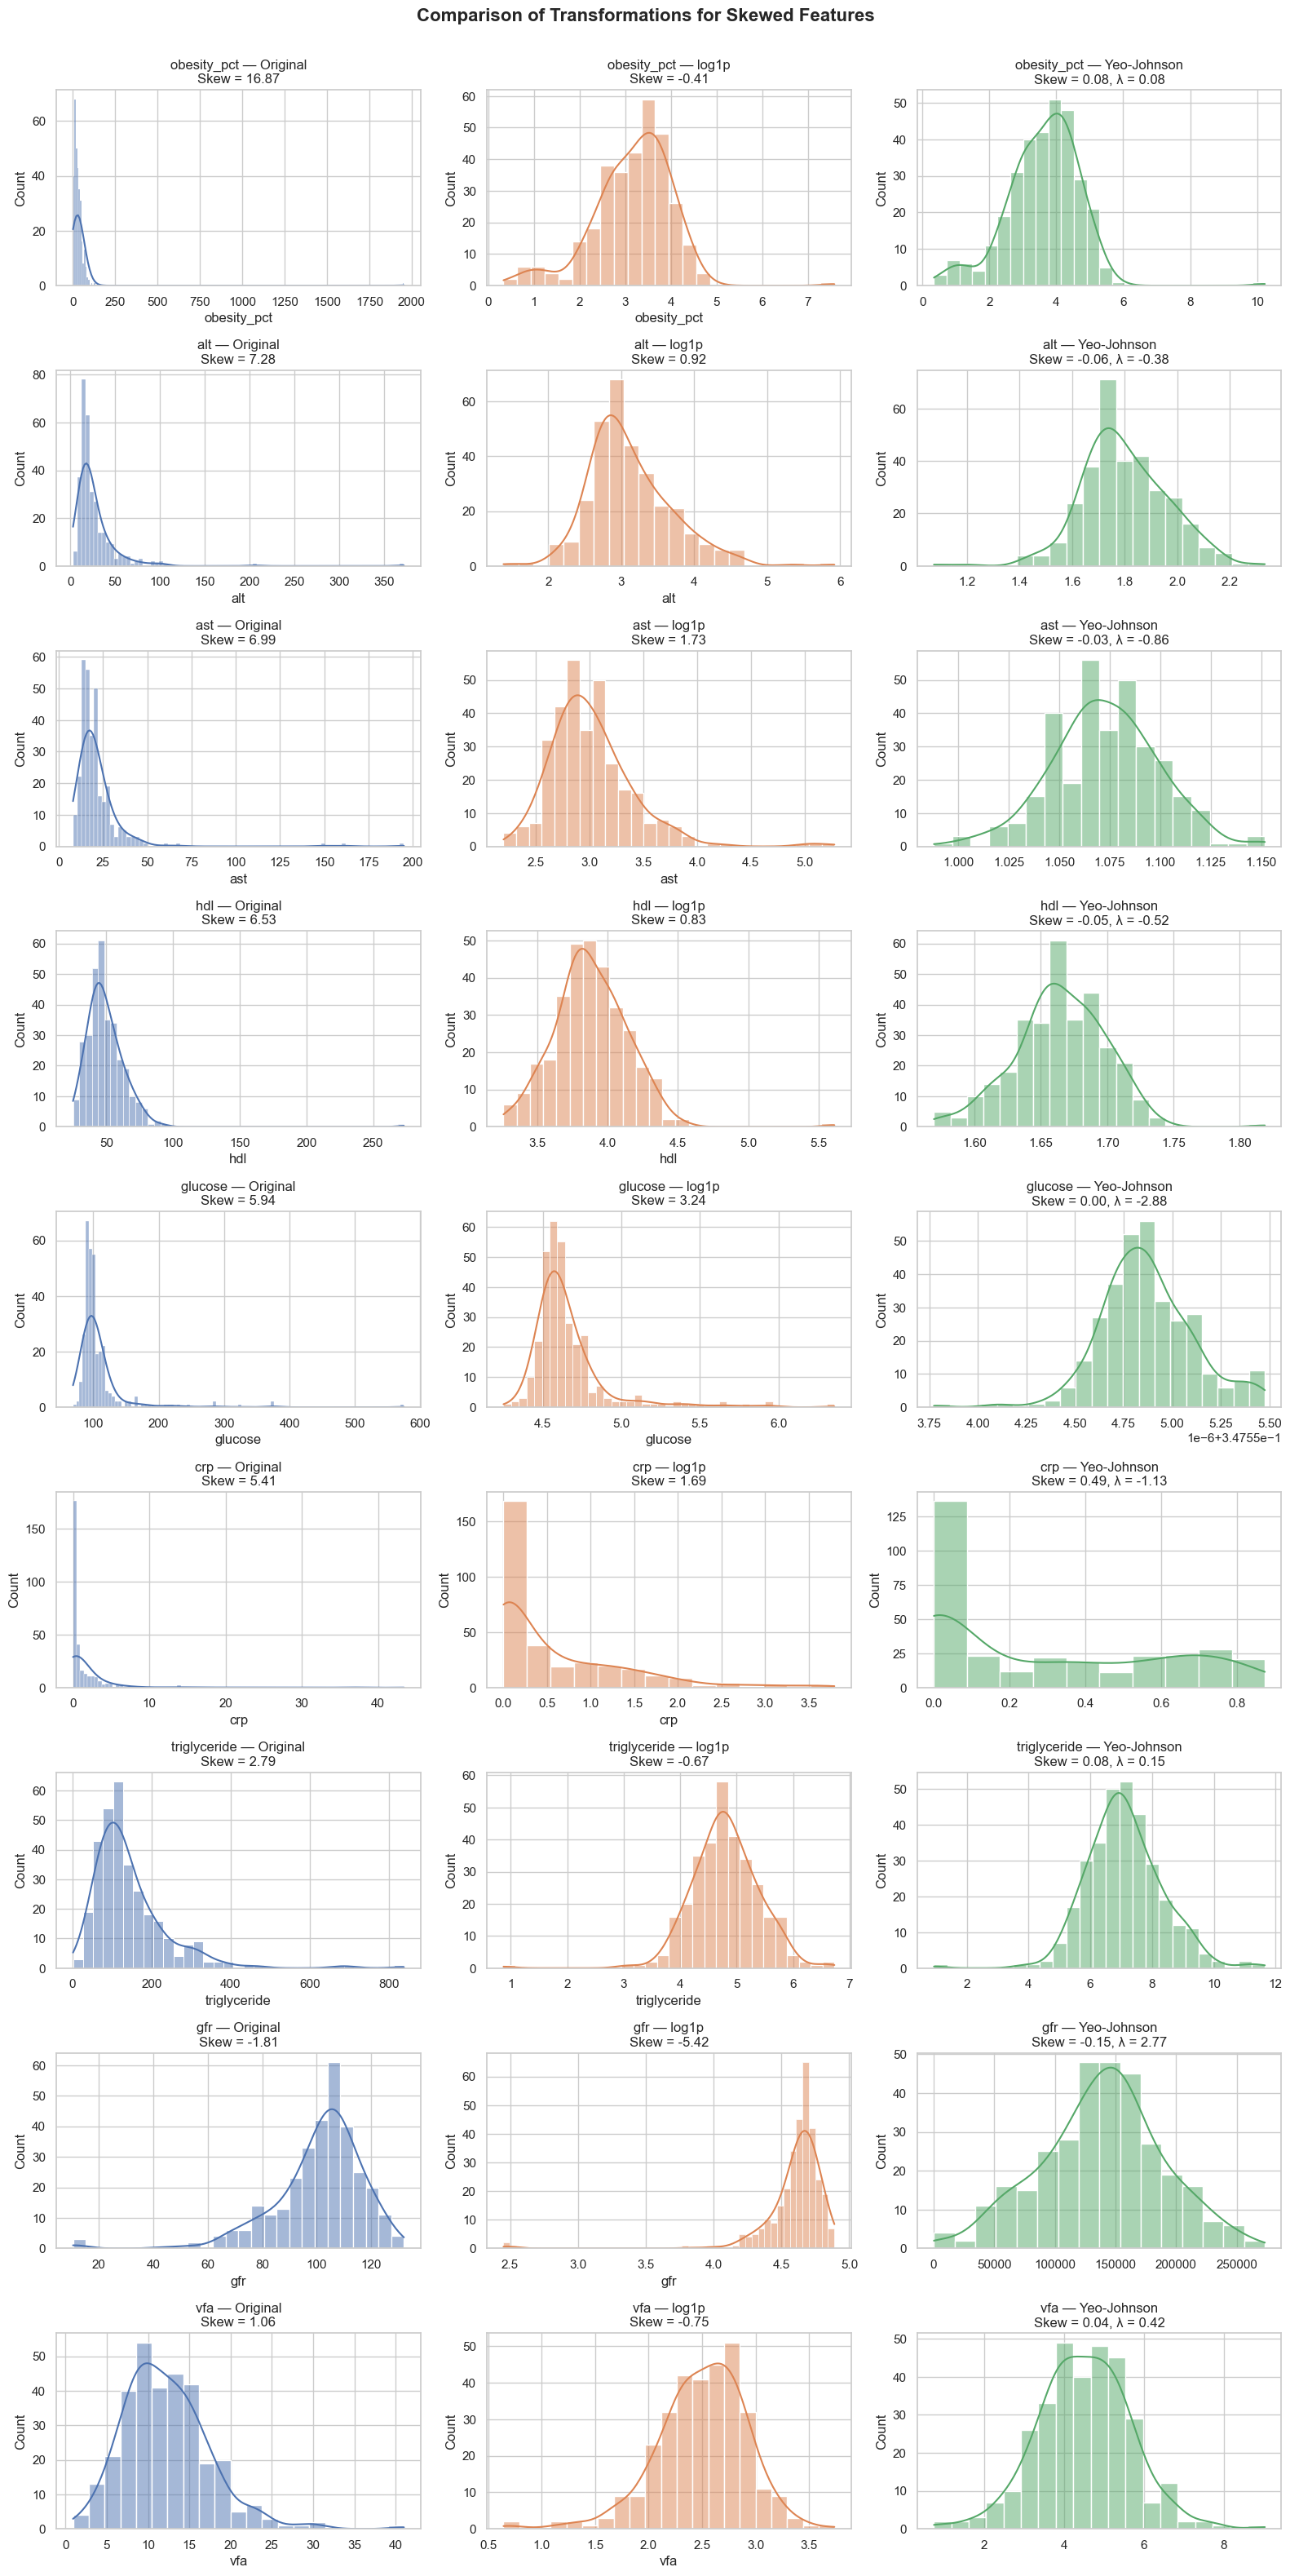

In [15]:
from scipy.stats import yeojohnson

# Features with substantial skewness
features_to_transform = skewness[
    skewness.abs() >= 1
].index.tolist()

n_features = len(features_to_transform)

# One row per feature, three transformation columns
fig, axes = plt.subplots(
    nrows=n_features,
    ncols=3,
    figsize=(16, 3.5 * n_features)
)

# Make axes always 2D, even if only one feature exists
if n_features == 1:
    axes = np.array([axes])

for i, col in enumerate(features_to_transform):

    original = df[col].dropna().astype(float)

    # -------------------------
    # 1. Original distribution
    # -------------------------
    sns.histplot(
        original,
        kde=True,
        ax=axes[i, 0],
        color="#4C72B0"
    )

    axes[i, 0].set_title(
        f"{col} — Original\n"
        f"Skew = {original.skew():.2f}"
    )

    # -------------------------
    # 2. log1p transformation
    # -------------------------
    if original.min() >= 0:

        logged = np.log1p(original)

        sns.histplot(
            logged,
            kde=True,
            ax=axes[i, 1],
            color="#DD8452"
        )

        axes[i, 1].set_title(
            f"{col} — log1p\n"
            f"Skew = {logged.skew():.2f}"
        )

    else:
        axes[i, 1].axis("off")
        axes[i, 1].text(
            0.5,
            0.5,
            "log1p not applicable\n(negative values present)",
            ha="center",
            va="center",
            fontsize=11
        )

    # -------------------------
    # 3. Yeo-Johnson
    # -------------------------
    yj_values, yj_lambda = yeojohnson(original)

    yj_skew = pd.Series(yj_values).skew()

    sns.histplot(
        yj_values,
        kde=True,
        ax=axes[i, 2],
        color="#55A868"
    )

    axes[i, 2].set_title(
        f"{col} — Yeo-Johnson\n"
        f"Skew = {yj_skew:.2f}, λ = {yj_lambda:.2f}"
    )

# Overall title
fig.suptitle(
    "Comparison of Transformations for Skewed Features",
    fontsize=16,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()
plt.show()

**Interpretation for this dataset:** the strongest right-skew candidates are expected to include `obesity_pct`, `glucose`, `hdl`, `triglyceride`, `ast`, `alt`, and `crp`; `vfa` is also slightly above the high-skew threshold. `gfr` is strongly left-skewed, so Yeo–Johnson is preferable to a simple log. The unusually large values driving `obesity_pct` and some laboratory variables should be verified before transformation—a transform can reduce their visual influence but cannot correct a data-entry or unit error.

## 6. Features versus gallstone status

,standardized_median_difference
vitamin_d,-0.88
tbfr_pct,0.64
lm_pct,-0.62
bm,-0.60
height,-0.50
tfc,0.49
creatinine,-0.43
tbw,-0.42
hgb,-0.40
vfa,0.36


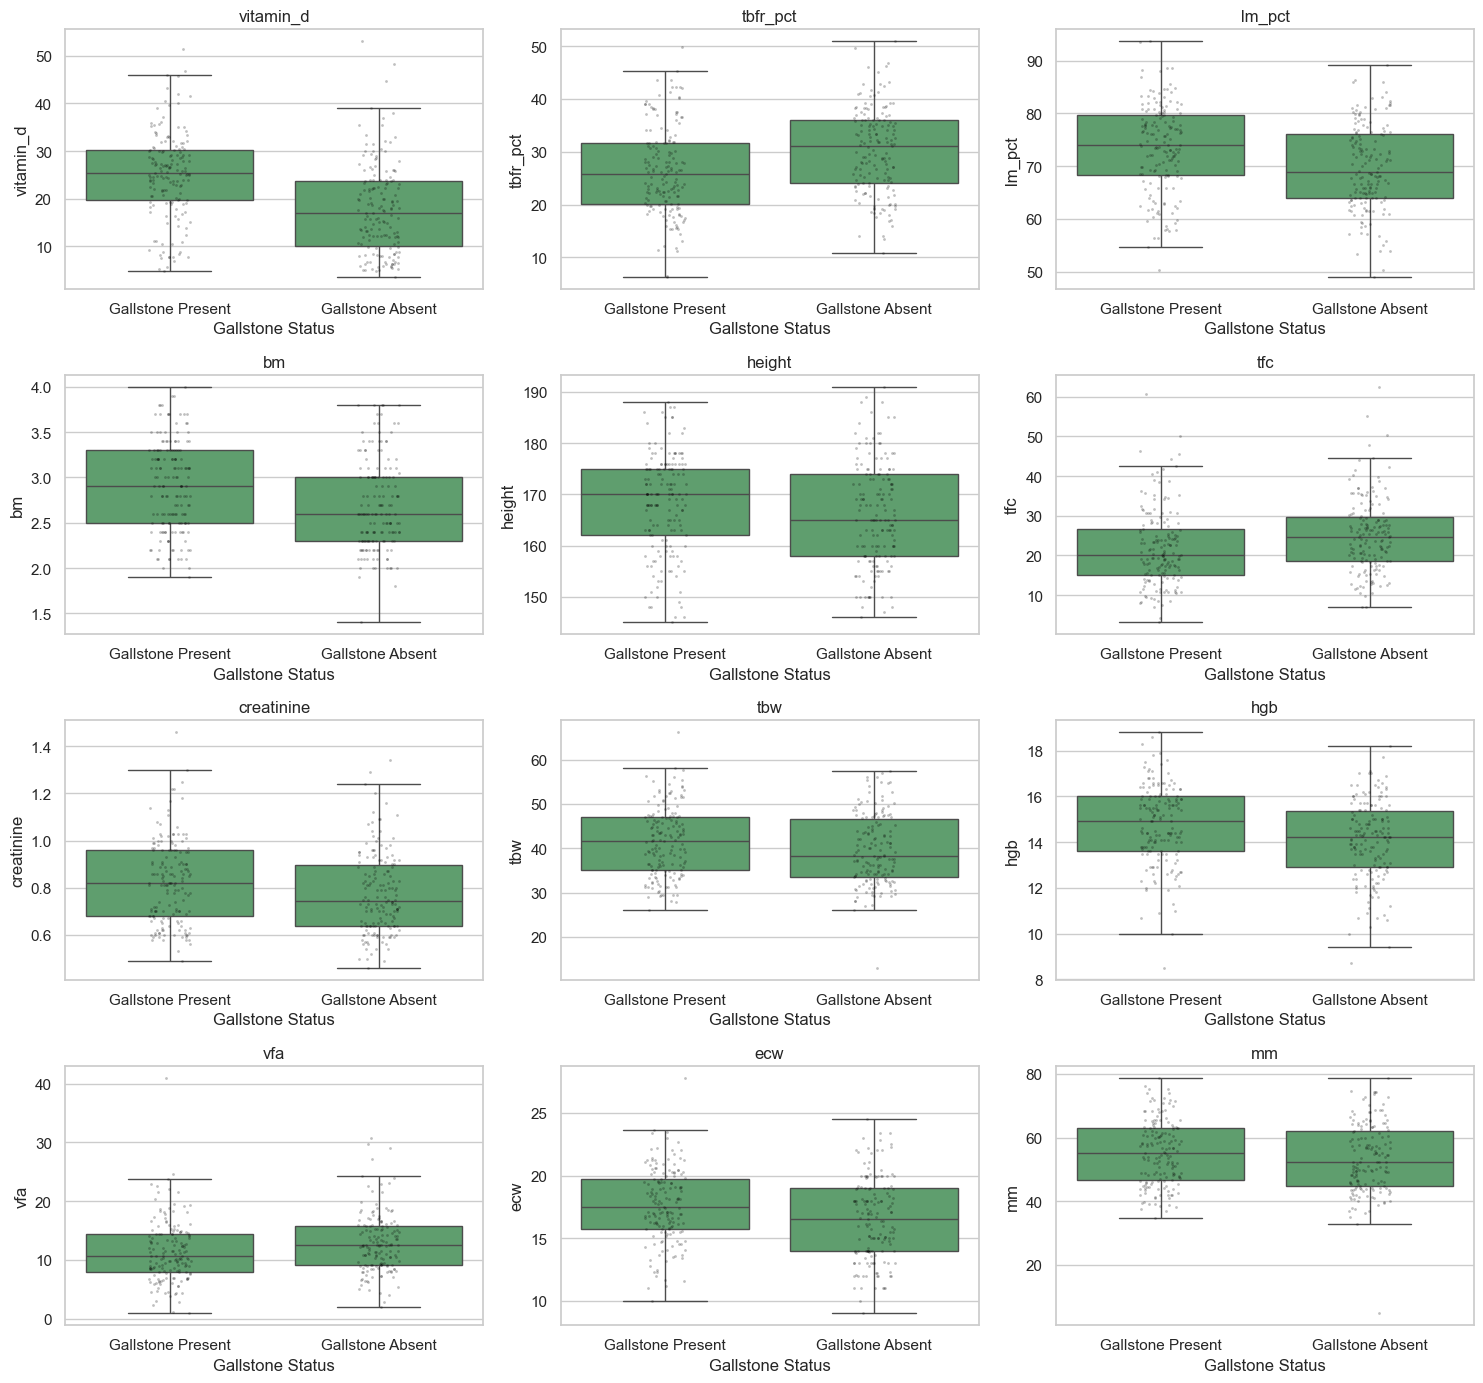

In [ ]:
# Standardized median differences help compare effects across different units.
classes = sorted(df[TARGET].dropna().unique())
if len(classes) == 2:
    g0, g1 = (df.loc[df[TARGET] == k, continuous_cols] for k in classes)
    pooled_sd = np.sqrt((g0.var() + g1.var()) / 2).replace(0, np.nan)
    smd = ((g1.median() - g0.median()) / pooled_sd).sort_values(key=abs, ascending=False)
    display(smd.rename("standardized_median_difference").to_frame())

    top_features = smd.abs().head(12).index.tolist()
    fig, axes = plt.subplots(4, 3, figsize=(15, 14))
    for ax, col in zip(axes.ravel(), top_features):
        sns.boxplot(x=df[TARGET].map(target_labels), y=df[col], order=list(target_labels.values()), ax=ax, color="#55A868", showfliers=False)
        sns.stripplot(x=df[TARGET].map(target_labels), y=df[col], order=list(target_labels.values()), ax=ax, color="black", alpha=.25, size=2)
        ax.set_xlabel('Gallstone Status')
        ax.set_title(col)
    plt.tight_layout(); plt.show()

In [ ]:
# Target prevalence within every coded category. Small groups should be interpreted cautiously.
for col in categorical_cols:
    tab = pd.crosstab(df[col], df[TARGET], margins=True)
    rate = df.groupby(col, dropna=False)[TARGET].agg(["count", "mean"]).rename(columns={"mean": "target_rate"})
    print(f"\n{col}")
    display(tab, rate.style.format({"target_rate": "{:.1%}"}))


gender


gallstone_status,0,1,All
gender,,,
0,94,68,162
1,67,90,157
All,161,158,319


,count,target_rate
gender,,
0,162,42.0%
1,157,57.3%



comorbidity


gallstone_status,0,1,All
comorbidity,,,
0,108,109,217
1,50,49,99
2,1,0,1
3,2,0,2
All,161,158,319


...

gallstone_status,0,1,All
dm,,,
0,145,131,276
1,16,27,43
All,161,158,319


,count,target_rate
dm,,
0,276,47.5%
1,43,62.8%



hfa


gallstone_status,0,1,All
hfa,,,
0,67,62,129
1,33,8,41
2,47,75,122
3,13,13,26
4,1,0,1
All,161,158,319


,count,target_rate
hfa,,
0,129,48.1%
1,41,19.5%
2,122,61.5%
3,26,50.0%
4,1,0.0%


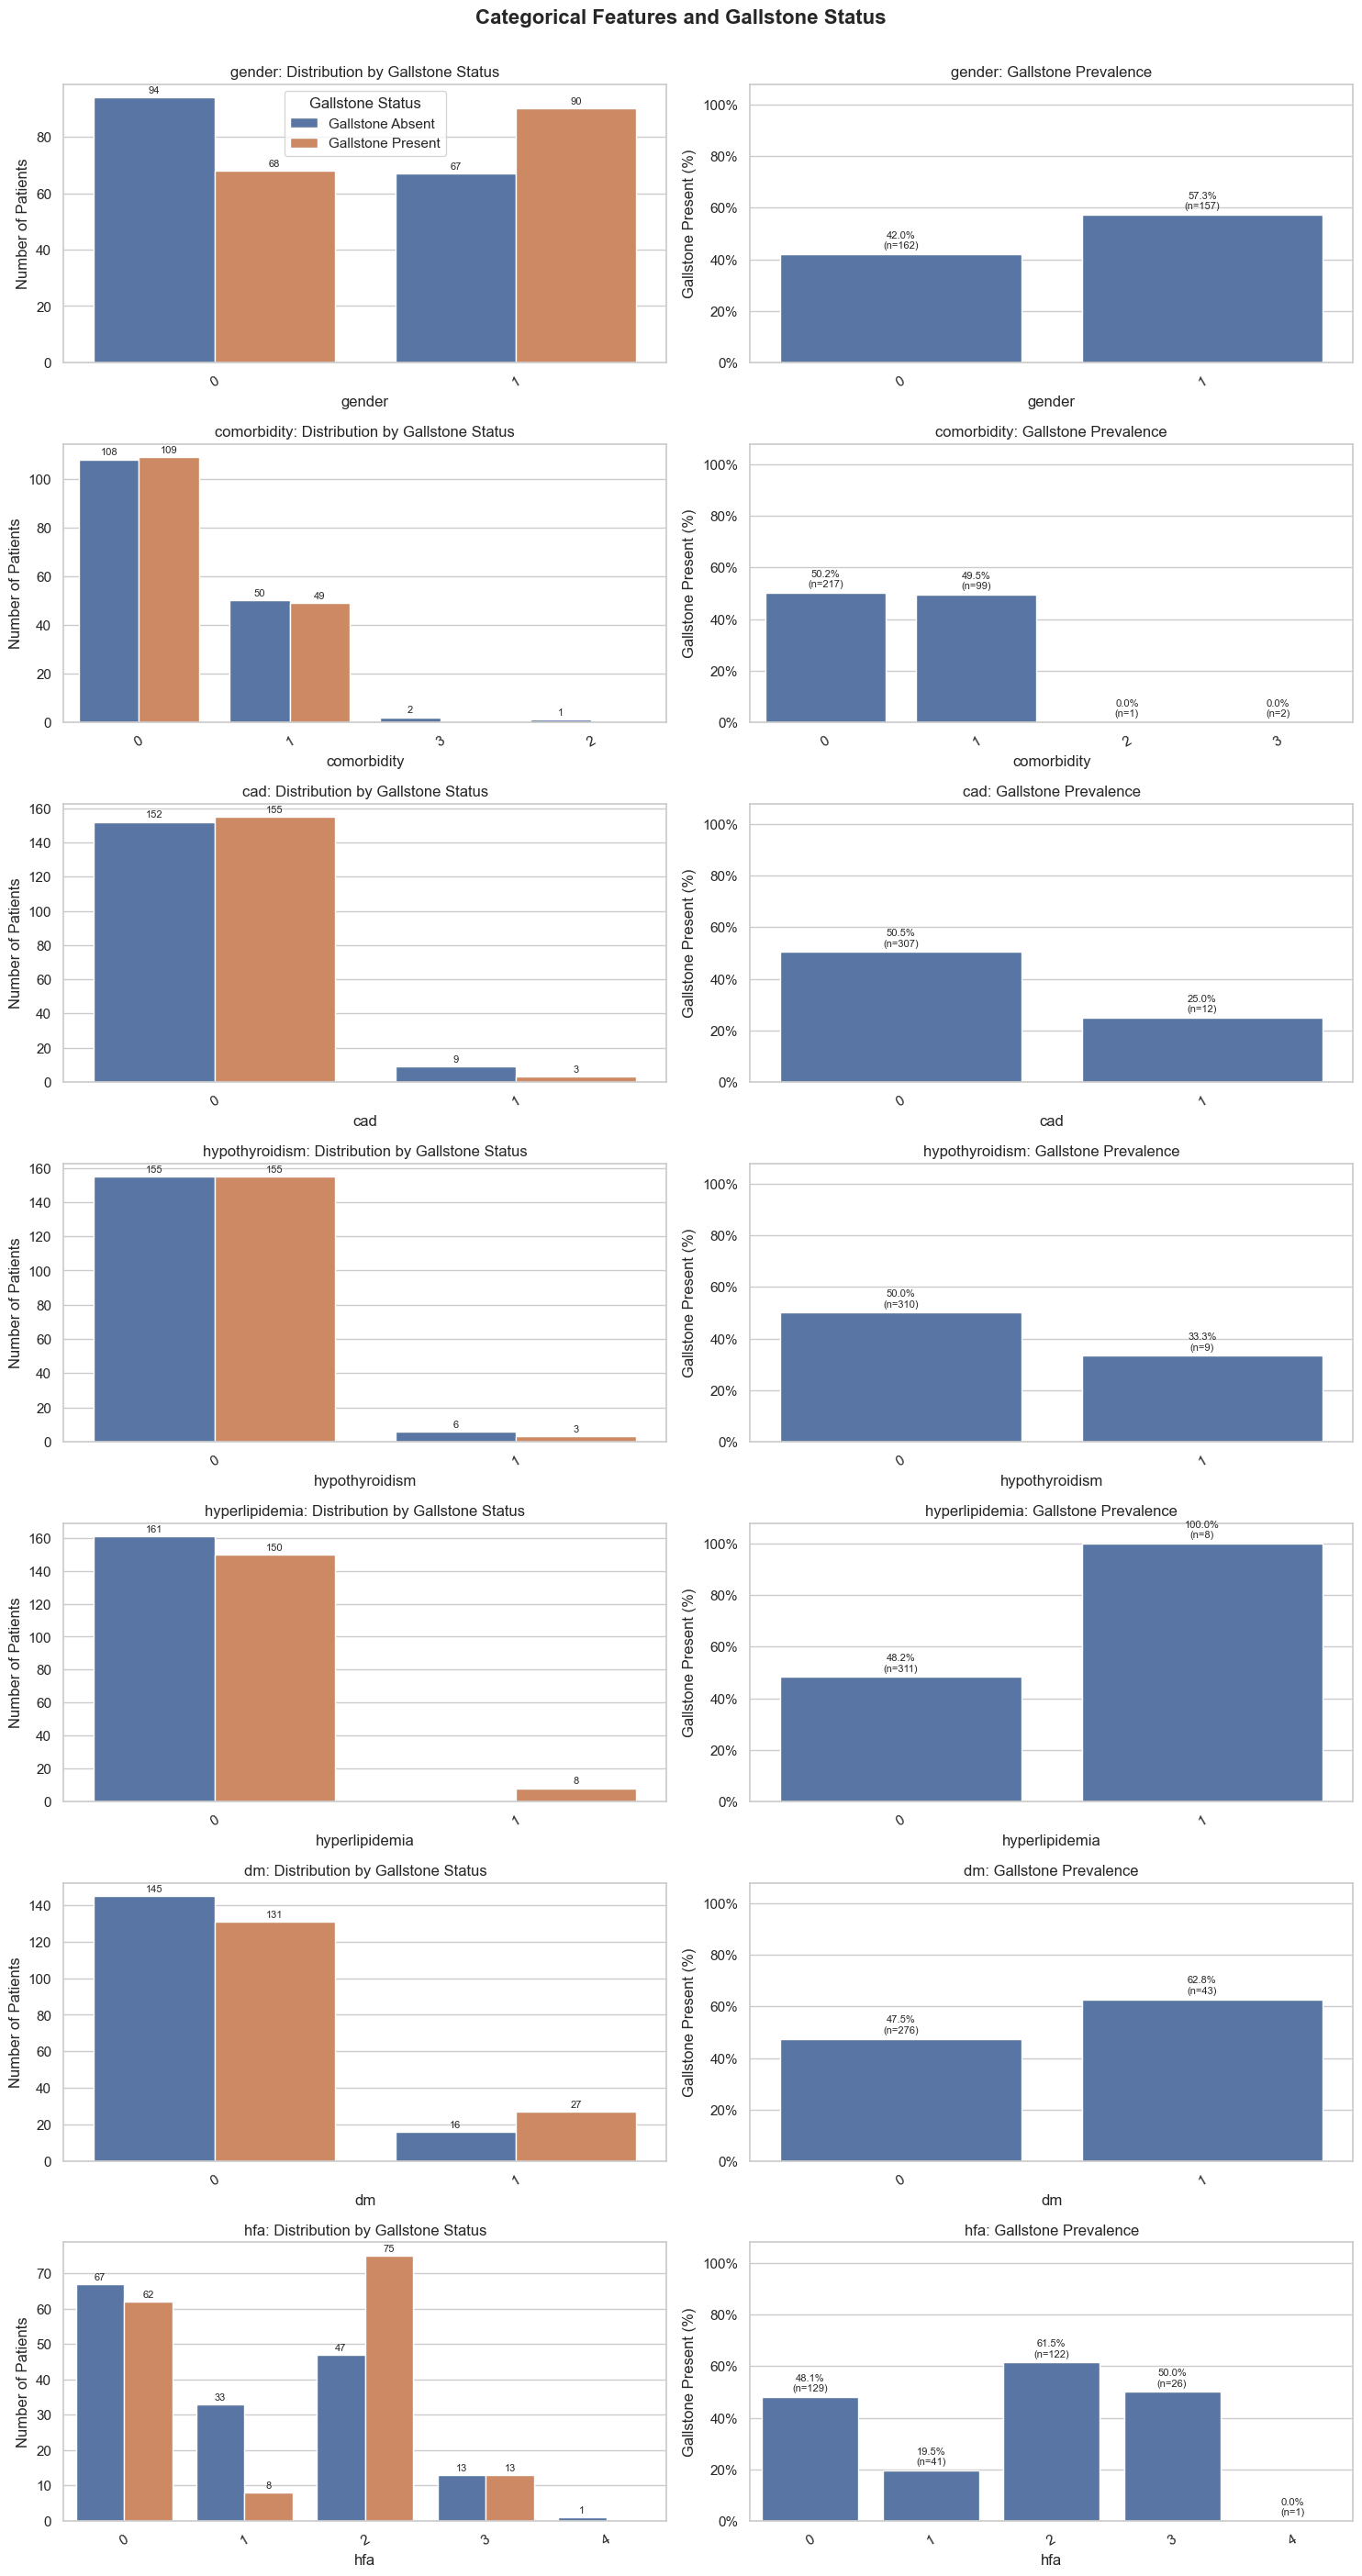

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# ----------------------------------------
# Human-readable target labels
# ----------------------------------------
target_labels = {
    0: "Gallstone Absent",
    1: "Gallstone Present"
}

plot_df = df.copy()

# Target label only for visualisation
plot_df["Gallstone Status"] = plot_df[TARGET].map(target_labels)

# Convert categorical variables to strings
# so coded categories appear clearly on the x-axis
for col in categorical_cols:
    plot_df[col] = (
        plot_df[col]
        .astype("string")
        .fillna("Missing")
    )


# ----------------------------------------
# Create one figure:
# one row per categorical feature
# two columns:
#   1. class counts
#   2. gallstone prevalence
# ----------------------------------------
n_features = len(categorical_cols)

fig, axes = plt.subplots(
    nrows=n_features,
    ncols=2,
    figsize=(15, 4 * n_features),
    squeeze=False
)

for i, col in enumerate(categorical_cols):

    # ==================================================
    # LEFT: category counts by Gallstone Status
    # ==================================================
    ax_count = axes[i, 0]

    sns.countplot(
        data=plot_df,
        x=col,
        hue="Gallstone Status",
        hue_order=["Gallstone Absent", "Gallstone Present"],
        ax=ax_count
    )

    ax_count.set_title(f"{col}: Distribution by Gallstone Status")
    ax_count.set_xlabel(col)
    ax_count.set_ylabel("Number of Patients")

    # Add count labels above bars
    for container in ax_count.containers:
        ax_count.bar_label(
            container,
            fmt="%d",
            padding=2,
            fontsize=8
        )

    ax_count.tick_params(
        axis="x",
        rotation=30
    )

    # Only show legend on first row
    if i == 0:
        ax_count.legend(
            title="Gallstone Status"
        )
    else:
        legend = ax_count.get_legend()
        if legend is not None:
            legend.remove()


    # ==================================================
    # RIGHT: Gallstone Present rate for each category
    # ==================================================

    # Calculate prevalence from original binary target
    temp = df[[col, TARGET]].copy()

    temp[col] = (
        temp[col]
        .astype("string")
        .fillna("Missing")
    )

    rate = (
        temp
        .groupby(col, dropna=False)[TARGET]
        .agg(
            count="count",
            target_rate="mean"
        )
        .reset_index()
    )

    ax_rate = axes[i, 1]

    sns.barplot(
        data=rate,
        x=col,
        y="target_rate",
        ax=ax_rate
    )

    ax_rate.set_title(
        f"{col}: Gallstone Prevalence"
    )

    ax_rate.set_xlabel(col)
    ax_rate.set_ylabel("Gallstone Present (%)")

    # Rate is stored between 0 and 1
    ax_rate.set_ylim(0, 1.08)

    ax_rate.yaxis.set_major_formatter(
        PercentFormatter(1.0)
    )

    ax_rate.tick_params(
        axis="x",
        rotation=30
    )

    # Add prevalence and sample size above each bar
    for patch, (_, row) in zip(
        ax_rate.patches,
        rate.iterrows()
    ):
        ax_rate.annotate(
            f"{row['target_rate']:.1%}\n(n={int(row['count'])})",
            (
                patch.get_x() + patch.get_width() / 2,
                patch.get_height()
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )


# ----------------------------------------
# Overall figure title
# ----------------------------------------
fig.suptitle(
    "Categorical Features and Gallstone Status",
    fontsize=16,
    fontweight="bold",
    y=1.002
)

plt.tight_layout()
plt.show()

## 7. Correlation and redundancy

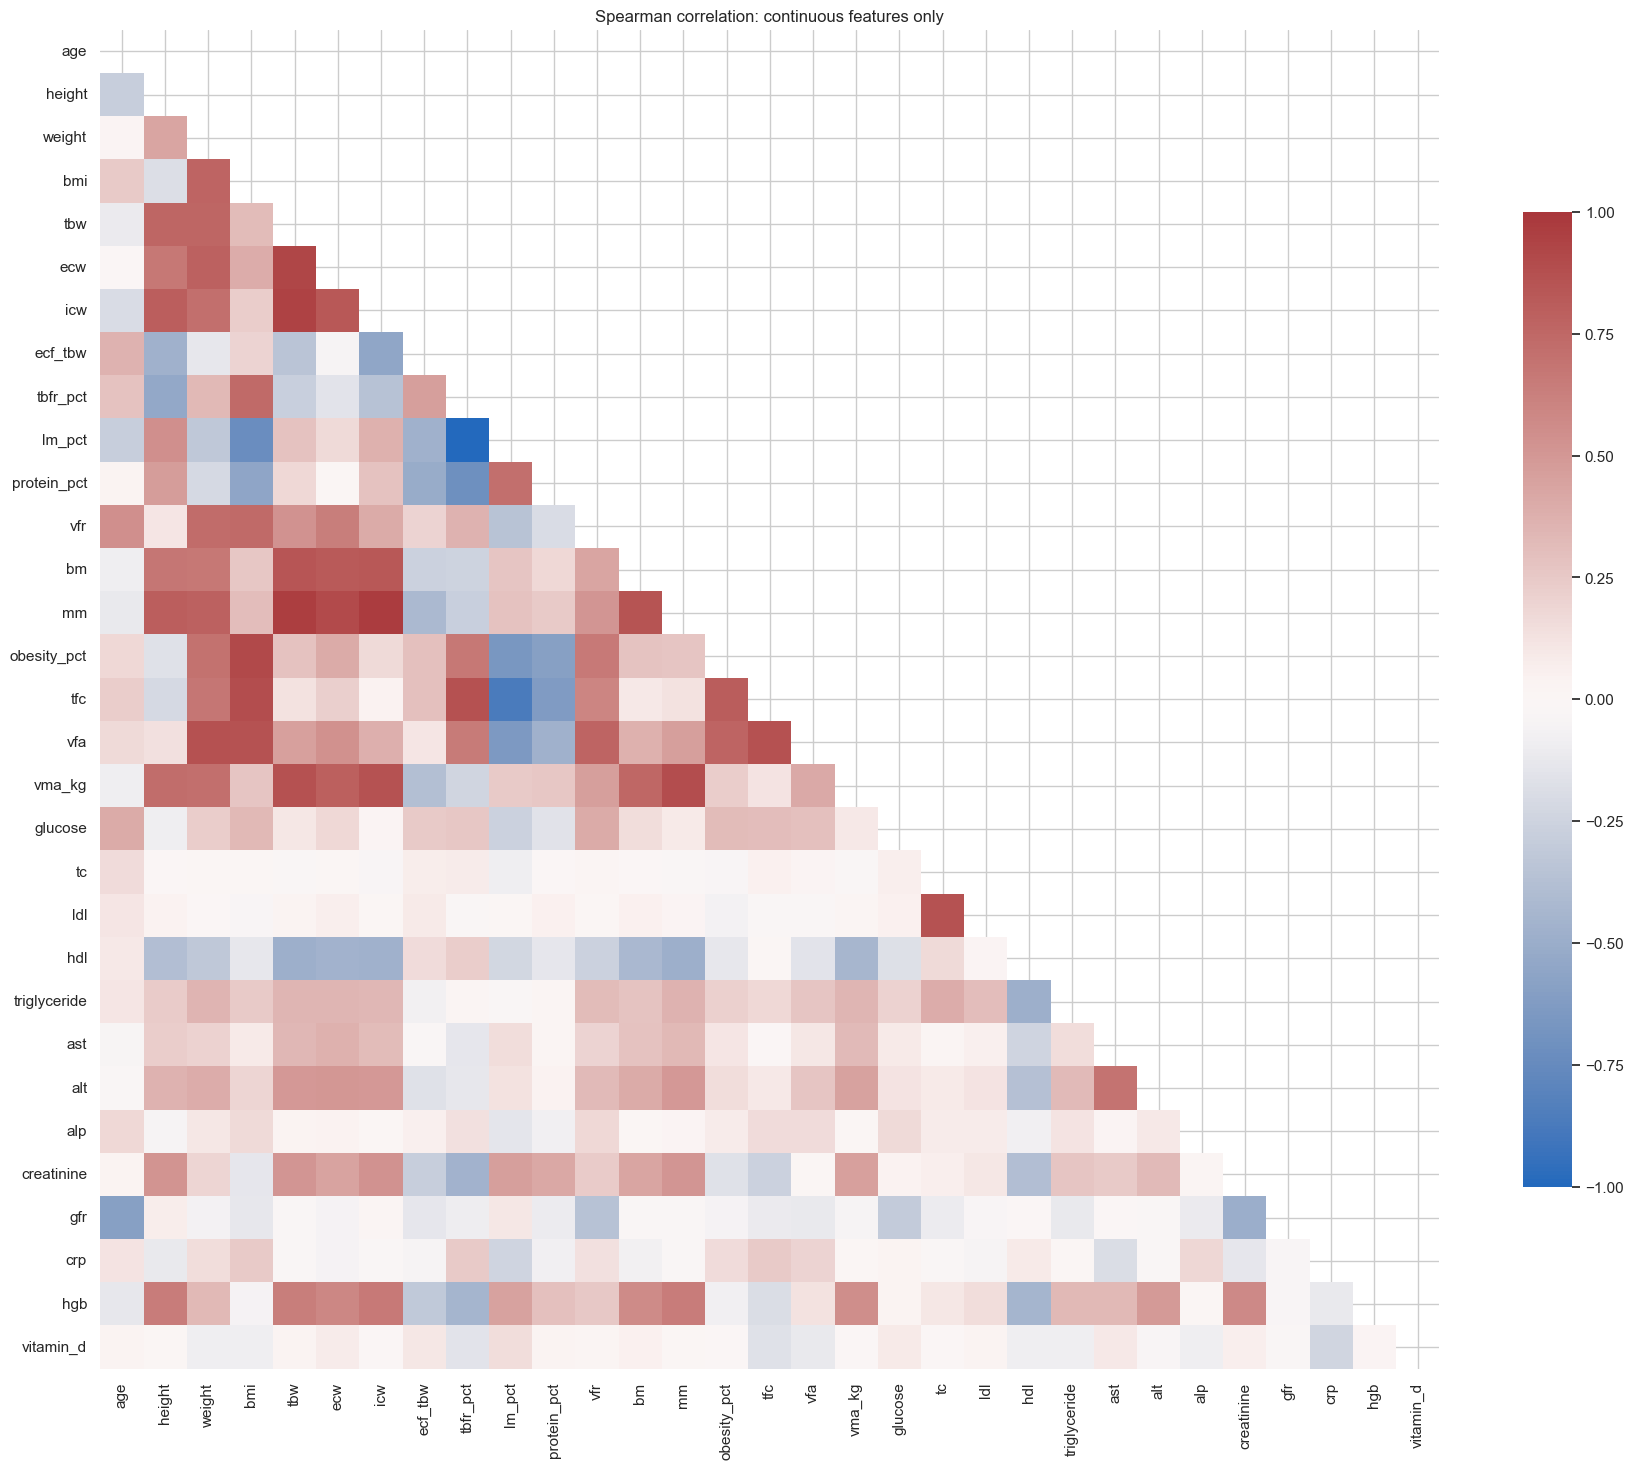

,spearman_with_target
crp,0.52
vitamin_d,-0.38
ast,-0.29
lm_pct,-0.23
tbfr_pct,0.23
bm,-0.22
tfc,0.19
hgb,-0.19
ecw,-0.18
hdl,0.17


In [ ]:
corr = df[continuous_cols].corr(method="spearman")
plt.figure(figsize=(18, 15))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7}, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation: continuous features only"); plt.tight_layout(); plt.show()

target_corr = df[continuous_cols].corrwith(df[TARGET], method='spearman').sort_values(key=abs, ascending=False)
display(target_corr.rename("spearman_with_target").to_frame())

In [ ]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (upper.stack().rename("rho").reset_index()
                .query("abs(rho) >= 0.80").sort_values("rho", key=abs, ascending=False))
print("Highly correlated feature pairs (|rho| ≥ 0.80):")
display(strong_pairs)

Highly correlated feature pairs (|rho| ≥ 0.80):


,level_0,level_1,rho
212,tbfr_pct,lm_pct,-0.99
171,icw,mm,0.98
122,tbw,mm,0.97
115,tbw,icw,0.94
114,tbw,ecw,0.93
97,bmi,obesity_pct,0.91
147,ecw,mm,0.90
98,bmi,tfc,0.89
315,mm,vma_kg,0.89
345,tfc,vfa,0.87


## 8. Outlier review

,feature,lower_fence,upper_fence,outliers,outlier_pct
28,crp,-2.42,4.04,34,10.66
24,alt,-9.38,53.62,27,8.46
18,glucose,66.50,134.50,25,7.84
23,ast,3.00,35.00,23,7.21
22,triglyceride,-50.50,305.50,20,6.27
27,gfr,69.31,135.61,13,4.08
25,alp,16.00,128.00,12,3.76
10,protein_pct,10.02,21.88,8,2.51
7,ecf_tbw,34.19,49.89,7,2.19
14,obesity_pct,-27.88,83.53,7,2.19


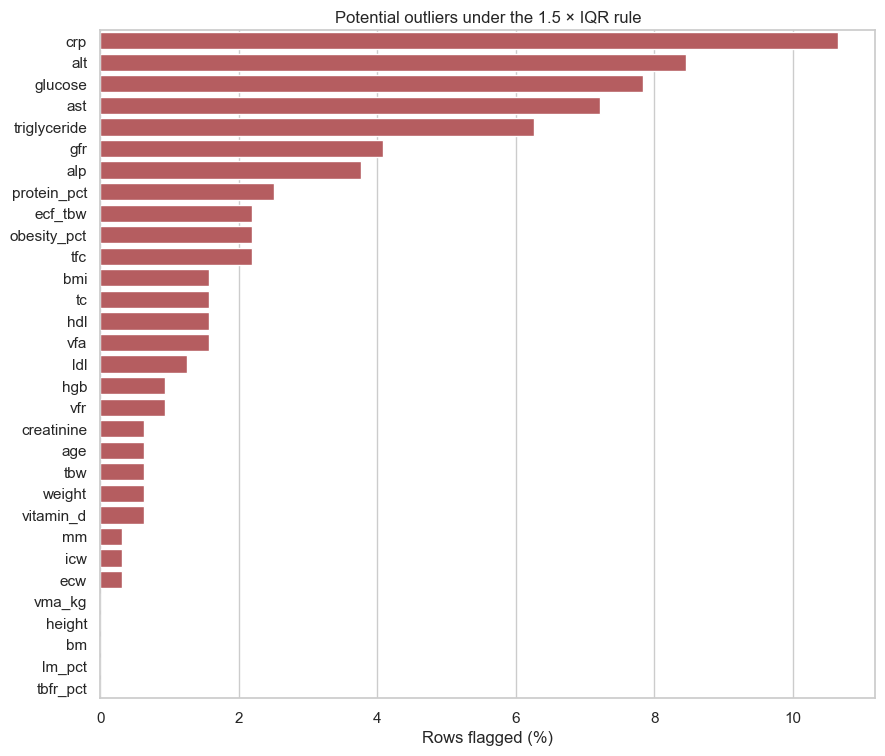

In [ ]:
outlier_rows = []
for col in continuous_cols:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = (df[col] < low) | (df[col] > high)
    outlier_rows.append({"feature": col, "lower_fence": low, "upper_fence": high,
                         "outliers": int(flag.sum()), "outlier_pct": flag.mean() * 100})
outliers = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outliers)

plt.figure(figsize=(10, max(6, len(outliers) * .28)))
sns.barplot(data=outliers, x="outlier_pct", y="feature", color="#C44E52")
plt.title("Potential outliers under the 1.5 × IQR rule"); plt.xlabel("Rows flagged (%)"); plt.ylabel("")
plt.show()

## 9. Explore the data in fewer dimensions

PCA summarises linear variation; t-SNE visualises local neighbourhoods. Use both to explore overlap, unusual observations, and redundant measurements. These plots are descriptive and do not establish diagnostic performance.

### 9.1 Prepare predictors without using the target

Use the continuous measurements defined in Section 3. Coded categories are excluded so their numeric codes do not imply distances; consequently these views do not represent every predictor. Replace infinite values with missing values, drop empty/constant columns, median-impute, then standardise to give measurements with different units comparable weight. No observations are removed. The target is used only for colouring.

This preprocessing is fitted to the complete dataset for EDA only. Fit new preprocessing and PCA on training data inside cross-validation for predictive modelling. Standardisation does not remove outlier influence or the extra weight given to families of correlated measurements.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

embedding_raw = df[continuous_cols].replace([np.inf, -np.inf], np.nan).copy()
embedding_features = embedding_raw.columns[embedding_raw.nunique(dropna=True) > 1].tolist()
excluded_embedding_features = [c for c in embedding_raw if c not in embedding_features]
if len(embedding_features) < 2 or len(df) < 6:
    raise ValueError("Dimensionality exploration requires at least two varying measurements and six rows.")
embedding_imputer = SimpleImputer(strategy="median")
embedding_scaler = StandardScaler()
X_embedding = embedding_scaler.fit_transform(
    embedding_imputer.fit_transform(embedding_raw[embedding_features])
)
embedding_labels = df[TARGET].map(target_labels).fillna('Missing')
embedding_hue_order = sorted(embedding_labels.unique())
embedding_palette = dict(zip(embedding_hue_order, sns.color_palette("tab10", len(embedding_hue_order))))
print(f"Embedding input: {X_embedding.shape[0]} rows × {X_embedding.shape[1]} continuous predictors")
print("Excluded empty/constant measurements:", excluded_embedding_features or "None")
print("Excluded categorical predictors:", categorical_cols)
print("Imputed cells:", int(embedding_raw[embedding_features].isna().sum().sum()))

Embedding input: 319 rows × 31 continuous predictors
Excluded empty/constant measurements: None
Excluded categorical predictors: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
Imputed cells: 0


### 9.2 PCA scree (elbow) and cumulative explained variance

The scree plot shows how much variance each component captures. A bend suggests diminishing returns, but may not identify a clear cutoff. The cumulative plot reports the components required to retain 80%, 90%, and 95% of variance. Explained variance measures predictor variation, not ability to predict gallstones.

,variance_retained,components_needed
0,0.80,9
1,0.90,13
2,0.95,16


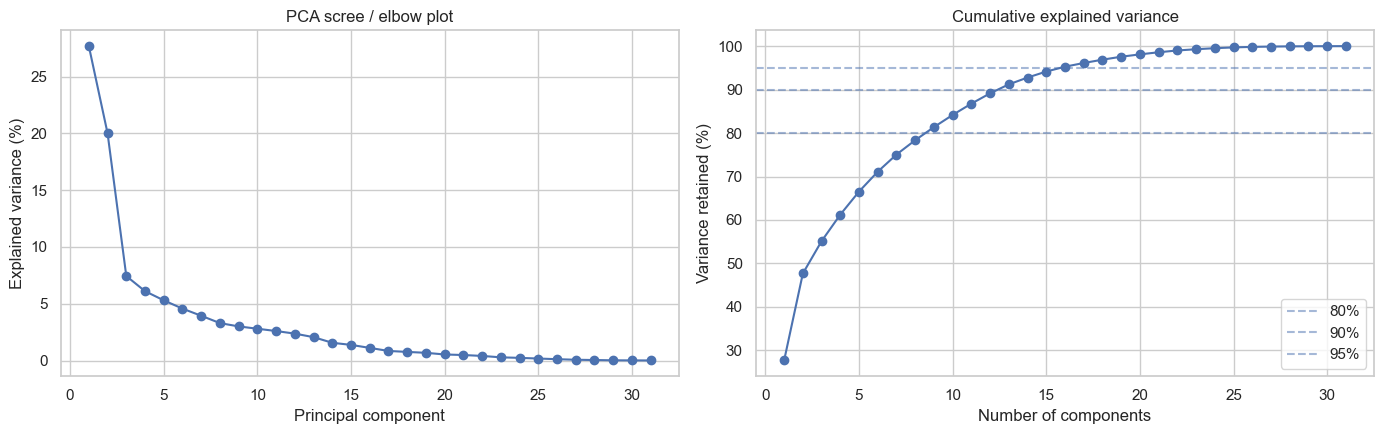

The 2D PCA view retains 47.7% of predictor variance.


In [ ]:
pca_eda = PCA(svd_solver="full")
X_pca_eda = pca_eda.fit_transform(X_embedding)
variance_ratio = pca_eda.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)
component_numbers = np.arange(1, len(variance_ratio) + 1)
variance_thresholds = pd.DataFrame({
    "variance_retained": [0.80, 0.90, 0.95],
    "components_needed": [int(np.searchsorted(cumulative_variance, t) + 1) for t in [0.80, 0.90, 0.95]],
})
display(variance_thresholds)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(component_numbers, 100 * variance_ratio, "o-")
axes[0].set(title="PCA scree / elbow plot", xlabel="Principal component", ylabel="Explained variance (%)")
axes[1].plot(component_numbers, 100 * cumulative_variance, "o-")
for threshold in [80, 90, 95]:
    axes[1].axhline(threshold, linestyle="--", alpha=0.5, label=f"{threshold}%")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Variance retained (%)")
axes[1].legend()
plt.tight_layout(); plt.show()
print(f"The 2D PCA view retains {cumulative_variance[1]:.1%} of predictor variance.")

### 9.3 Two-dimensional PCA and component weights

Each dot is a row; colours show gallstone status (Yes = 0, No = 1). Overlap in two dimensions can hide structure in later components. The weight plot shows the measurements contributing most strongly to the first two component directions. Component signs are arbitrary; these weights are not feature importance for predicting the target.

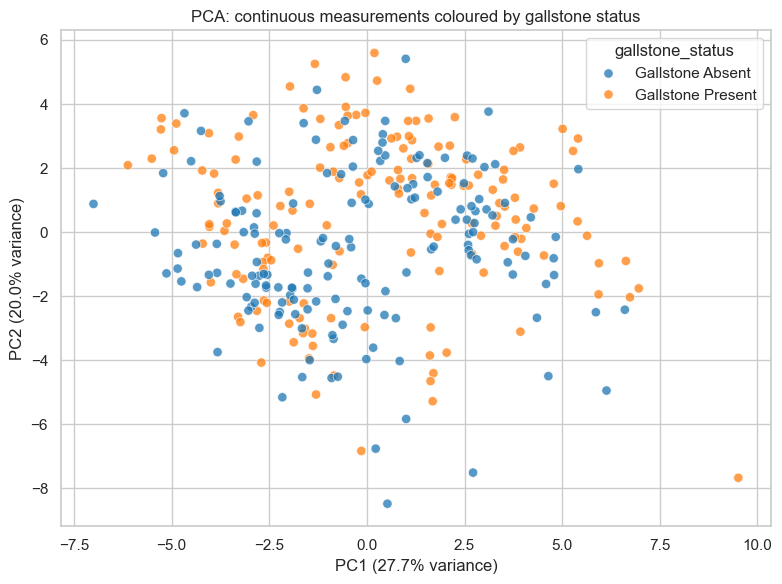

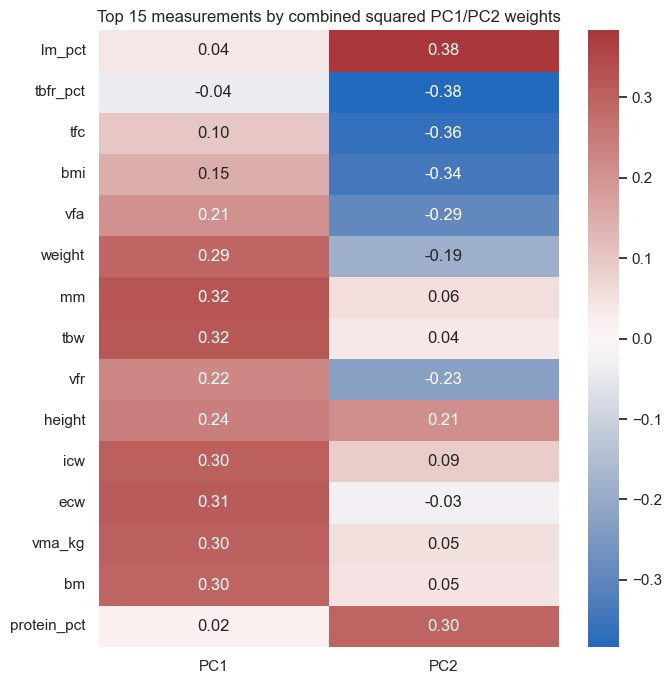

In [ ]:
pca_view = pd.DataFrame(X_pca_eda[:, :2], columns=["PC1", "PC2"], index=df.index)
pca_view[TARGET] = embedding_labels
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pca_view, x="PC1", y="PC2", hue=TARGET,
                hue_order=embedding_hue_order, palette=embedding_palette, alpha=0.75, s=45, ax=ax)
ax.set(title="PCA: continuous measurements coloured by gallstone status",
       xlabel=f"PC1 ({variance_ratio[0]:.1%} variance)", ylabel=f"PC2 ({variance_ratio[1]:.1%} variance)")
plt.tight_layout(); plt.show()
pca_weights = pd.DataFrame(pca_eda.components_[:2].T, index=embedding_features, columns=["PC1", "PC2"])
top_weight_features = pca_weights.pow(2).sum(axis=1).nlargest(15).index
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(pca_weights.loc[top_weight_features], cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Top 15 measurements by combined squared PC1/PC2 weights")
plt.tight_layout(); plt.show()

### 9.4 t-SNE: compare neighbourhood settings

Perplexity controls the approximate neighbourhood size. Compare several settings instead of selecting the picture with the clearest target separation. t-SNE axes have no measurement units; distances between separate islands, island sizes, and their relative positions are not reliable measures of global structure. t-SNE does not provide explained variance or a PCA-style elbow plot.

All panels use the same seed for reproducibility. Trustworthiness (closer to 1 is better) describes preservation of local neighbours from the standardised input, not target prediction. Repeat with other seeds before drawing conclusions about stable structure.

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: invalid value encountered in mat

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: invalid value encountered in mat

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: invalid value encountered in mat

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


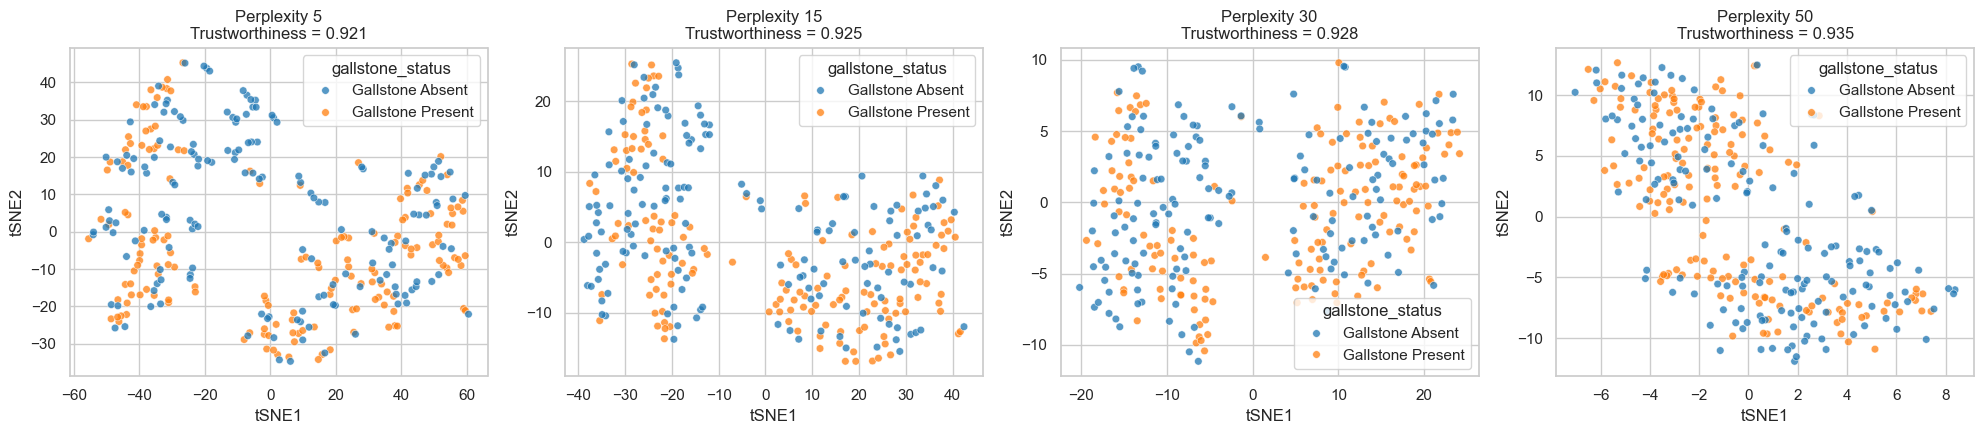

,perplexity,trustworthiness
0,5,0.92
1,15,0.93
2,30,0.93
3,50,0.94


In [ ]:
perplexities = [p for p in [5, 15, 30, 50] if p < len(X_embedding)]
trust_neighbors = min(10, (len(X_embedding) - 1) // 2)
fig, axes = plt.subplots(1, len(perplexities), figsize=(5 * len(perplexities), 4.5), squeeze=False)
tsne_quality = []
tsne_embeddings = {}
for ax, perplexity in zip(axes.ravel(), perplexities):
    coordinates = TSNE(n_components=2, perplexity=perplexity, init="pca",
                       learning_rate="auto", random_state=RANDOM_STATE).fit_transform(X_embedding)
    tsne_embeddings[perplexity] = coordinates
    score = trustworthiness(X_embedding, coordinates, n_neighbors=trust_neighbors)
    tsne_quality.append({"perplexity": perplexity, "trustworthiness": score})
    view = pd.DataFrame(coordinates, columns=["tSNE1", "tSNE2"], index=df.index)
    view[TARGET] = embedding_labels
    sns.scatterplot(data=view, x="tSNE1", y="tSNE2", hue=TARGET,
                    hue_order=embedding_hue_order, palette=embedding_palette, s=30, alpha=0.75, ax=ax)
    ax.set_title(f"Perplexity {perplexity}\nTrustworthiness = {score:.3f}")
plt.tight_layout(); plt.show()
display(pd.DataFrame(tsne_quality).round(3))

### 9.5 K-means elbow and silhouette diagnostics

This is a separate elbow plot for choosing a possible number of clusters. Fit K-means on the full standardised continuous predictor space, **not** on the t-SNE map. Inertia always decreases as clusters are added; inspect diminishing improvements together with silhouette scores (higher indicates better separation; values near zero suggest overlap). Neither guarantees that meaningful clusters exist. K-means favours compact, roughly spherical groups and is sensitive to outliers and correlated measurements.

The highest silhouette score in this limited search supplies an exploratory example, not a confirmed cluster count. The PCA projection below may hide separation present in other dimensions. Target proportions are examined only after fitting; cluster IDs are arbitrary and are not diagnoses.

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-

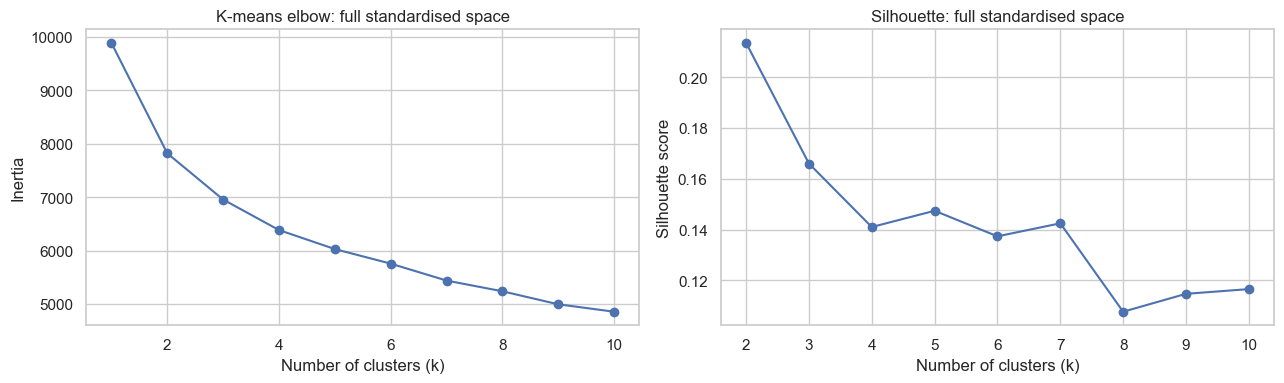

,k,inertia,silhouette
0,1,"9,889.00",NaN
1,2,"7,820.80",0.21
2,3,"6,954.75",0.17
3,4,"6,383.13",0.14
4,5,"6,027.05",0.15
5,6,"5,754.40",0.14
6,7,"5,437.11",0.14
7,8,"5,236.53",0.11
8,9,"4,992.71",0.11
9,10,"4,853.71",0.12


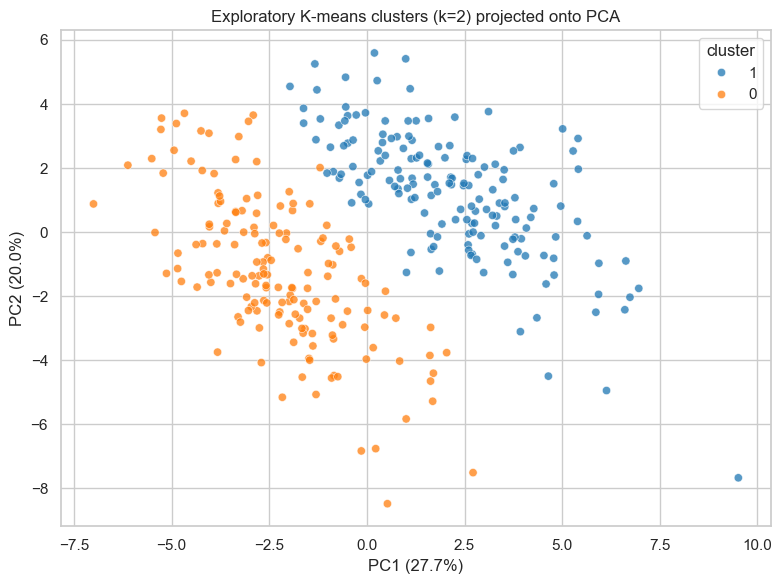

Cluster counts by target code:


gallstone_status,Gallstone Absent,Gallstone Present
cluster,,
0,89,68
1,69,93


Within-cluster target proportions:


gallstone_status,Gallstone Absent,Gallstone Present
cluster,,
0,0.57,0.43
1,0.43,0.57


In [ ]:
max_k = min(10, len(X_embedding) - 1, len(np.unique(X_embedding, axis=0)))
cluster_models, cluster_rows = {}, []
for k in range(1, max_k + 1):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_embedding)
    cluster_models[k] = model
    n_labels = len(np.unique(model.labels_))
    score = silhouette_score(X_embedding, model.labels_) if 1 < n_labels < len(X_embedding) else np.nan
    cluster_rows.append({"k": k, "inertia": model.inertia_, "silhouette": score})
cluster_diagnostics = pd.DataFrame(cluster_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(cluster_diagnostics.k, cluster_diagnostics.inertia, "o-")
axes[0].set(title="K-means elbow: full standardised space", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(cluster_diagnostics.k, cluster_diagnostics.silhouette, "o-")
axes[1].set(title="Silhouette: full standardised space", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout(); plt.show()
display(cluster_diagnostics)
valid_scores = cluster_diagnostics.dropna(subset=["silhouette"])
if not valid_scores.empty:
    exploratory_k = int(valid_scores.loc[valid_scores.silhouette.idxmax(), "k"])
    cluster_labels = cluster_models[exploratory_k].labels_
    cluster_view = pca_view.assign(cluster=pd.Series(cluster_labels, index=df.index).astype(str))
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=cluster_view, x="PC1", y="PC2", hue="cluster", palette="tab10", alpha=0.75, ax=ax)
    ax.set(title=f"Exploratory K-means clusters (k={exploratory_k}) projected onto PCA",
           xlabel=f"PC1 ({variance_ratio[0]:.1%})", ylabel=f"PC2 ({variance_ratio[1]:.1%})")
    plt.tight_layout(); plt.show()
    print("Cluster counts by target code:")
    display(pd.crosstab(cluster_view["cluster"], embedding_labels))
    print("Within-cluster target proportions:")
    display(pd.crosstab(cluster_view["cluster"], embedding_labels, normalize="index"))
else:
    print("No valid silhouette scores; inspect unique rows before interpreting clusters.")

### 9.6 Further EDA worth doing

- **Sensitivity to extreme values:** repeat these views after validating unusual `obesity_pct` and laboratory values, and compare Yeo–Johnson preprocessing with the standardised original measurements. Track whether the same rows form isolated groups; do not remove them merely to improve a plot.
- **Sensitivity to redundancy:** compare a reduced set of body-composition measurements against all continuous predictors. Correlated features can dominate distance-based methods even after scaling.
- **Categorical structure:** compare the existing category counts and target proportions with group sizes visible. A mixed-data distance or mixed-data factor method would be needed to include coded categories appropriately in a joint embedding.
- **Pairwise relationships:** use scatterplots for the strongest correlated pairs from Section 7, coloured by target, to check nonlinearity and whether a few observations drive the correlation.
- **Uncertainty and stability:** add uncertainty intervals to group comparisons, repeat t-SNE with other seeds, and compare cluster assignments across resamples before describing any group as stable.
- **Data provenance:** check repeated patients, collection batches, measurement units, and when features were recorded relative to the outcome if these details become available.

Record how much variance the PCA view retains, which measurements drive its axes, whether local patterns persist across t-SNE settings, and whether silhouette scores support distinct groups. Visual separation alone is not evidence of predictive accuracy.


**Results from this run:** PC1 and PC2 retain **47.7%** of the standardised continuous-feature variance. Retaining 80%, 90%, and 95% requires **9, 13, and 16 components**, respectively. The largest silhouette score among k=2–10 is approximately **0.21 at k=2**, suggesting substantial overlap rather than strongly separated clusters. Interpret the 2D maps alongside the original feature distributions.


## 10. Automated findings and modelling checklist

The following cell produces a compact, data-driven summary. Before modelling:

- Obtain the data dictionary and map category codes to labels.
- Split train/test data **before** fitting imputers, scalers, encoders, or feature selection. Stratify by the target.
- Investigate clinically implausible values; do not delete IQR outliers automatically.
- Review strongly correlated body-composition measures to control redundancy and unstable coefficients.
- Use cross-validation and metrics suited to the observed class balance (for example ROC-AUC plus precision/recall).
- Treat all target associations as exploratory and validate them on independent data.

In [ ]:
minority_share = target_counts.min() / target_counts.sum()
print(f"Dataset size: {len(df):,} rows, {df.shape[1]} analysis columns")
print(f"Missing cells: {df.isna().sum().sum():,} ({df.isna().mean().mean():.2%} of all cells)")
print(f"Duplicate rows: {duplicate_rows:,}")
print(f"Minority-class share: {minority_share:.1%}")
if 'target_corr' in globals():
    print("Largest absolute Spearman associations with target:")
    display(target_corr.head(10).rename("rho").to_frame())
print(f"Strongly correlated predictor pairs: {len(strong_pairs):,}")
print("Most frequently IQR-flagged features:")
display(outliers.head(10))

Dataset size: 319 rows, 39 analysis columns
Missing cells: 0 (0.00% of all cells)
Duplicate rows: 0
Minority-class share: 49.5%
Largest absolute Spearman associations with target:


,rho
crp,0.52
vitamin_d,-0.38
ast,-0.29
lm_pct,-0.23
tbfr_pct,0.23
bm,-0.22
tfc,0.19
hgb,-0.19
ecw,-0.18
hdl,0.17


Strongly correlated predictor pairs: 24
Most frequently IQR-flagged features:


,feature,lower_fence,upper_fence,outliers,outlier_pct
28,crp,-2.42,4.04,34,10.66
24,alt,-9.38,53.62,27,8.46
18,glucose,66.50,134.50,25,7.84
23,ast,3.00,35.00,23,7.21
22,triglyceride,-50.50,305.50,20,6.27
27,gfr,69.31,135.61,13,4.08
25,alp,16.00,128.00,12,3.76
10,protein_pct,10.02,21.88,8,2.51
7,ecf_tbw,34.19,49.89,7,2.19
14,obesity_pct,-27.88,83.53,7,2.19
